# 05 — Train and evaluate the first logistic-regression baseline

This notebook creates the first complete credit-risk model using the ten numeric `static_0` features studied earlier.

It answers four basic questions:

1. Can the pipeline learn from earlier applications and score later applications?
2. Does it rank defaults above non-defaults better than a constant baseline?
3. Are its predicted probabilities useful and reasonably calibrated?
4. Is its ranking performance stable across validation weeks?

The model is a benchmark, not the final solution. Weeks 72–91 remain locked and are not scored here.

## Modeling design

```text
Training:               weeks 0–51
Development validation: weeks 52–71
Locked final holdout:   weeks 72–91
```

The scikit-learn pipeline contains median imputation, missing indicators, scaling, and logistic regression. Keeping these operations together prevents different preprocessing rules from being applied during training and prediction.

`class_weight=None` is intentional for this first probability baseline. We evaluate imbalance with ROC AUC and precision-recall AUC rather than relying on accuracy.

In [1]:
from pathlib import Path
from time import perf_counter
import gc

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.calibration import calibration_curve
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    PrecisionRecallDisplay,
    RocCurveDisplay,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    log_loss,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)

RANDOM_STATE = 42

## Locate the files and declare the predictors

`case_id` is used only to identify an application. `WEEK_NUM` controls time splitting, and `target` is the answer. None of those three columns is passed into the model.

In [2]:
possible_roots = [Path.cwd(), Path.cwd().parent]
project_dir = next(
    (path for path in possible_roots if (path / "data" / "parquet_files" / "train" / "train_base.parquet").exists()),
    None,
)
if project_dir is None:
    raise FileNotFoundError("Run this notebook from the project root or the notebooks folder.")

train_dir = project_dir / "data" / "parquet_files" / "train"
report_dir = project_dir / "reports" / "baseline_10_logistic"
artifact_dir = project_dir / "artifacts"
report_dir.mkdir(parents=True, exist_ok=True)
artifact_dir.mkdir(parents=True, exist_ok=True)

selected_features = [
    "credamount_770A",
    "annuity_780A",
    "maininc_215A",
    "applications30d_658L",
    "numactivecreds_622L",
    "totaldebt_9A",
    "avgdbddpdlast24m_3658932P",
    "avgdpdtolclosure24_3658938P",
    "clientscnt12m_3712952L",
    "price_1097A",
]

print("Project:", project_dir)
print("Predictor count:", len(selected_features))

Project: D:\Home Credit - Credit Risk Model Stability
Predictor count: 10


## Load and join the minimum required data

Only eleven columns are read from `static_0`: the join key and ten predictors. The two physical Parquet files are row partitions of one logical table.

In [3]:
base = pd.read_parquet(
    train_dir / "train_base.parquet",
    columns=["case_id", "WEEK_NUM", "target"],
)

static_paths = [
    train_dir / "train_static_0_0.parquet",
    train_dir / "train_static_0_1.parquet",
]
static = pd.concat(
    [
        pd.read_parquet(path, columns=["case_id", *selected_features])
        for path in static_paths
    ],
    ignore_index=True,
)

assert base["case_id"].is_unique
assert static["case_id"].is_unique

modeling_data = base.merge(
    static,
    on="case_id",
    how="left",
    validate="one_to_one",
    indicator=True,
)
assert modeling_data["_merge"].eq("both").all(), "Some base cases did not match static_0."
modeling_data = modeling_data.drop(columns="_merge")

del base, static
gc.collect()

print(f"Modeling data: {modeling_data.shape[0]:,} rows × {modeling_data.shape[1]} columns")
print(f"Approximate memory: {modeling_data.memory_usage(deep=True).sum() / 1024**2:,.1f} MB")

Modeling data: 1,526,659 rows × 13 columns
Approximate memory: 151.4 MB


## Make the time split and lock the final period

We can inspect training and development-validation targets. For the locked period, this notebook reports only row count and week range. It does not create features, predictions, or performance metrics for those rows.

In [4]:
train_mask = modeling_data["WEEK_NUM"].between(0, 51)
valid_mask = modeling_data["WEEK_NUM"].between(52, 71)
locked_mask = modeling_data["WEEK_NUM"].between(72, 91)

membership_count = train_mask.astype("int8") + valid_mask.astype("int8") + locked_mask.astype("int8")
assert membership_count.eq(1).all()
assert modeling_data.loc[train_mask, "WEEK_NUM"].max() < modeling_data.loc[valid_mask, "WEEK_NUM"].min()
assert modeling_data.loc[valid_mask, "WEEK_NUM"].max() < modeling_data.loc[locked_mask, "WEEK_NUM"].min()

X_train = modeling_data.loc[train_mask, selected_features].copy()
y_train = modeling_data.loc[train_mask, "target"].astype("int8").copy()
X_valid = modeling_data.loc[valid_mask, selected_features].copy()
y_valid = modeling_data.loc[valid_mask, "target"].astype("int8").copy()
valid_metadata = modeling_data.loc[valid_mask, ["case_id", "WEEK_NUM"]].copy()

assert X_train.columns.tolist() == selected_features
assert X_valid.columns.tolist() == selected_features
assert y_train.nunique() == 2 and y_valid.nunique() == 2

split_summary = pd.DataFrame({
    "period": ["Training", "Development validation", "Locked final holdout"],
    "weeks": ["0–51", "52–71", "72–91"],
    "rows": [int(train_mask.sum()), int(valid_mask.sum()), int(locked_mask.sum())],
    "default_rate_percent": [100 * y_train.mean(), 100 * y_valid.mean(), np.nan],
})
display(split_summary.style.format({"rows": "{:,.0f}", "default_rate_percent": "{:.3f}"}, na_rep="Locked"))

print(
    "Locked holdout preserved:",
    f"{locked_mask.sum():,} rows,",
    f"weeks {modeling_data.loc[locked_mask, 'WEEK_NUM'].min()}–{modeling_data.loc[locked_mask, 'WEEK_NUM'].max()}",
)

del modeling_data, train_mask, valid_mask, locked_mask, membership_count
gc.collect()

,period,weeks,rows,default_rate_percent
0,Training,0–51,"1,065,921",3.089
1,Development validation,52–71,"248,535",4.188
2,Locked final holdout,72–91,"212,203",Locked


Locked holdout preserved: 212,203 rows, weeks 72–91


34

## Define one end-to-end pipeline

Calling `fit` on this object performs every learned step using training rows only:

1. Learn training medians and missing-indicator columns.
2. Learn training means and standard deviations.
3. Fit logistic-regression coefficients.

Later, `predict_proba` automatically reuses those exact transformations.

In [5]:
baseline_model = Pipeline([
    (
        "preprocess",
        Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median",
                    add_indicator=True,
                    keep_empty_features=True,
                ),
            ),
            ("scaler", StandardScaler()),
        ]),
    ),
    (
        "model",
        LogisticRegression(
            max_iter=500,
            class_weight=None,
            solver="lbfgs",
            random_state=RANDOM_STATE,
        ),
    ),
])

baseline_model

Pipeline(steps=[('preprocess',
                 Pipeline(steps=[('imputer',
                                  SimpleImputer(add_indicator=True,
                                                keep_empty_features=True,
                                                strategy='median')),
                                 ('scaler', StandardScaler())])),
                ('model', LogisticRegression(max_iter=500, random_state=42))])

## Train the model

This is the only `fit` call. Validation is never passed to it.

In [6]:
fit_started = perf_counter()
baseline_model.fit(X_train, y_train)
fit_seconds = perf_counter() - fit_started

iterations = int(baseline_model.named_steps["model"].n_iter_[0])
print(f"Training completed in {fit_seconds:,.2f} seconds")
print(f"Logistic-regression iterations: {iterations}")
assert iterations < baseline_model.named_steps["model"].max_iter, "The solver reached max_iter; review convergence."

Training completed in 2.74 seconds
Logistic-regression iterations: 14


## Generate probability scores

For binary logistic regression, `predict_proba(... )[:, 1]` returns the estimated probability of `target = 1`. Every value must be between 0 and 1.

In [7]:
train_probability = baseline_model.predict_proba(X_train)[:, 1]
valid_probability = baseline_model.predict_proba(X_valid)[:, 1]

assert np.isfinite(train_probability).all()
assert np.isfinite(valid_probability).all()
assert ((train_probability >= 0) & (train_probability <= 1)).all()
assert ((valid_probability >= 0) & (valid_probability <= 1)).all()

probability_summary = pd.DataFrame({
    "training": pd.Series(train_probability).describe(percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]),
    "validation": pd.Series(valid_probability).describe(percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]),
})
display(probability_summary)

,training,validation
count,1.065921e+06,248535.000000
mean,3.089306e-02,0.031706
std,1.206932e-02,0.017208
min,1.619379e-03,0.011143
1%,2.065915e-02,0.020440
5%,2.392889e-02,0.023507
50%,2.837269e-02,0.028456
95%,4.370701e-02,0.047006
99%,6.840806e-02,0.081670
max,9.699719e-01,0.986510


## Evaluate ranking and probability quality

- **ROC AUC:** probability that a randomly chosen default receives a higher risk score than a randomly chosen non-default. `0.50` is random ranking and `1.00` is perfect ranking.
- **Gini:** `2 × AUC − 1`. It expresses the same ranking information on a different scale.
- **PR AUC / average precision:** emphasizes finding the rare default class. Its simple reference level is close to the default rate.
- **Log loss and Brier score:** assess probability quality. Lower values are better.

The constant comparison predicts the training default rate for every validation application. It has no ranking ability but provides a useful probability baseline.

In [8]:
def metric_row(name, y_true, probability):
    auc = roc_auc_score(y_true, probability)
    return {
        "evaluation": name,
        "rows": len(y_true),
        "actual_default_rate": float(np.mean(y_true)),
        "mean_predicted_probability": float(np.mean(probability)),
        "roc_auc": auc,
        "gini": 2 * auc - 1,
        "pr_auc_average_precision": average_precision_score(y_true, probability),
        "log_loss": log_loss(y_true, probability),
        "brier_score": brier_score_loss(y_true, probability),
    }

training_default_rate = float(y_train.mean())
constant_valid_probability = np.full(len(y_valid), training_default_rate)

performance = pd.DataFrame([
    metric_row("Training — model", y_train, train_probability),
    metric_row("Validation — constant baseline", y_valid, constant_valid_probability),
    metric_row("Validation — logistic model", y_valid, valid_probability),
]).set_index("evaluation")

performance.to_csv(report_dir / "performance_metrics.csv")
display(performance.style.format({
    "rows": "{:,.0f}",
    "actual_default_rate": "{:.4%}",
    "mean_predicted_probability": "{:.4%}",
    "roc_auc": "{:.4f}",
    "gini": "{:.4f}",
    "pr_auc_average_precision": "{:.4f}",
    "log_loss": "{:.5f}",
    "brier_score": "{:.5f}",
}))

,rows,actual_default_rate,mean_predicted_probability,roc_auc,gini,pr_auc_average_precision,log_loss,brier_score
evaluation,,,,,,,,
Training — model,"1,065,921",3.0893%,3.0893%,0.5692,0.1384,0.0467,0.13641,0.02985
Validation — constant baseline,"248,535",4.1881%,3.0893%,0.5000,0.0000,0.0419,0.17570,0.04025
Validation — logistic model,"248,535",4.1881%,3.1706%,0.6085,0.2169,0.0723,0.17244,0.04006


## Visualize ranking and probability calibration

The ROC and precision-recall curves measure ranking. The calibration chart compares average predicted risk with the observed default rate in groups of similar predictions.

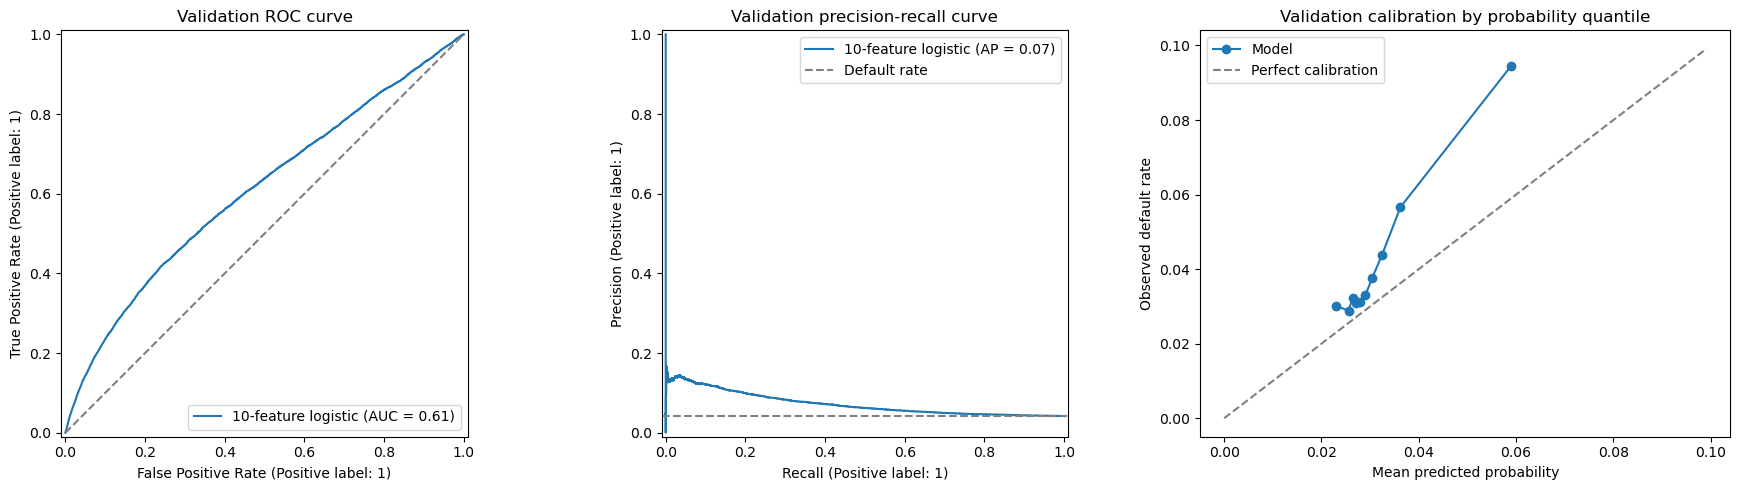

In [9]:
fraction_positive, mean_predicted = calibration_curve(
    y_valid,
    valid_probability,
    n_bins=10,
    strategy="quantile",
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

RocCurveDisplay.from_predictions(y_valid, valid_probability, ax=axes[0], name="10-feature logistic")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random")
axes[0].set_title("Validation ROC curve")

PrecisionRecallDisplay.from_predictions(y_valid, valid_probability, ax=axes[1], name="10-feature logistic")
axes[1].axhline(y_valid.mean(), linestyle="--", color="grey", label="Default rate")
axes[1].set_title("Validation precision-recall curve")
axes[1].legend()

axes[2].plot(mean_predicted, fraction_positive, marker="o", label="Model")
limit = max(mean_predicted.max(), fraction_positive.max()) * 1.05
axes[2].plot([0, limit], [0, limit], linestyle="--", color="grey", label="Perfect calibration")
axes[2].set_xlabel("Mean predicted probability")
axes[2].set_ylabel("Observed default rate")
axes[2].set_title("Validation calibration by probability quantile")
axes[2].legend()

fig.tight_layout()
plt.show()

## Inspect risk deciles

Applications are divided into ten equally sized groups using validation predictions. Decile 10 contains the highest predicted risk. A useful ranking model should show higher observed default rates in higher-risk deciles.

,risk_decile,applications,defaults,observed_default_rate,mean_predicted_probability,minimum_probability,maximum_probability,cumulative_application_share_from_highest_risk,cumulative_default_capture_from_highest_risk,lift_over_validation_average
0,1,"24,854",749,3.014%,2.294%,1.114%,2.482%,100.000%,100.000%,0.72×
1,2,"24,853",718,2.889%,2.557%,2.482%,2.603%,90.000%,92.804%,0.69×
2,3,"24,854",804,3.235%,2.643%,2.603%,2.678%,80.000%,85.906%,0.77×
3,4,"24,853",769,3.094%,2.713%,2.678%,2.752%,70.000%,78.182%,0.74×
4,5,"24,854",773,3.110%,2.797%,2.752%,2.846%,60.000%,70.795%,0.74×
5,6,"24,853",819,3.295%,2.901%,2.846%,2.961%,50.000%,63.368%,0.79×
6,7,"24,853",932,3.750%,3.039%,2.961%,3.125%,40.000%,55.500%,0.90×
7,8,"24,854","1,091",4.390%,3.247%,3.125%,3.395%,30.000%,46.546%,1.05×
8,9,"24,853","1,408",5.665%,3.625%,3.395%,3.942%,20.000%,36.065%,1.35×
9,10,"24,854","2,346",9.439%,5.891%,3.943%,98.651%,10.000%,22.538%,2.25×


Highest-risk concentration:


,highest_risk_share,applications,observed_default_rate,default_capture_rate,lift_over_validation_average
0,5%,"12,427",11.322%,13.517%,2.70×
1,10%,"24,854",9.439%,22.538%,2.25×
2,20%,"49,707",7.552%,36.065%,1.80×


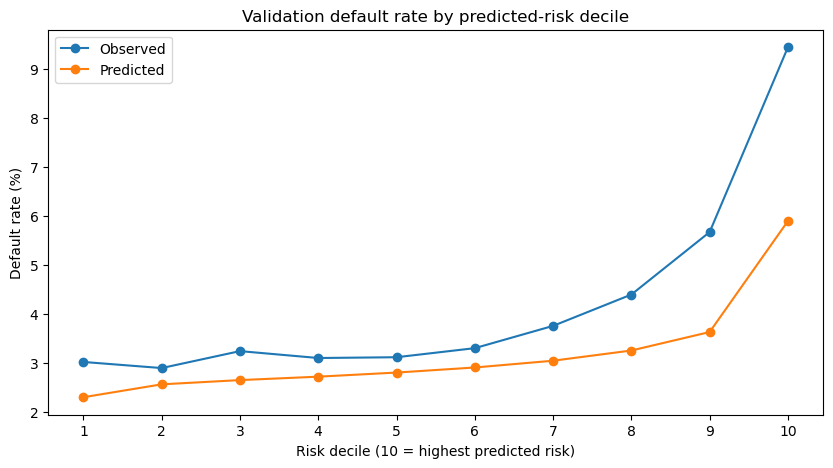

In [10]:
validation_predictions = valid_metadata.copy()
validation_predictions["target"] = y_valid.to_numpy()
validation_predictions["probability_default"] = valid_probability
validation_predictions["risk_decile"] = (
    pd.qcut(
        validation_predictions["probability_default"],
        q=10,
        labels=False,
        duplicates="drop",
    )
    + 1
)

risk_deciles = (
    validation_predictions
    .groupby("risk_decile", observed=True)
    .agg(
        applications=("target", "size"),
        defaults=("target", "sum"),
        observed_default_rate=("target", "mean"),
        mean_predicted_probability=("probability_default", "mean"),
        minimum_probability=("probability_default", "min"),
        maximum_probability=("probability_default", "max"),
    )
    .reset_index()
)

descending = risk_deciles.sort_values("risk_decile", ascending=False).copy()
descending["cumulative_application_share_from_highest_risk"] = descending["applications"].cumsum() / descending["applications"].sum()
descending["cumulative_default_capture_from_highest_risk"] = descending["defaults"].cumsum() / descending["defaults"].sum()
risk_deciles = risk_deciles.merge(
    descending[[
        "risk_decile",
        "cumulative_application_share_from_highest_risk",
        "cumulative_default_capture_from_highest_risk",
    ]],
    on="risk_decile",
    how="left",
)
risk_deciles["lift_over_validation_average"] = (
    risk_deciles["observed_default_rate"] / y_valid.mean()
)

risk_deciles.to_csv(report_dir / "risk_decile_summary.csv", index=False)
display(risk_deciles.style.format({
    "applications": "{:,.0f}",
    "defaults": "{:,.0f}",
    "observed_default_rate": "{:.3%}",
    "mean_predicted_probability": "{:.3%}",
    "minimum_probability": "{:.3%}",
    "maximum_probability": "{:.3%}",
    "cumulative_application_share_from_highest_risk": "{:.3%}",
    "cumulative_default_capture_from_highest_risk": "{:.3%}",
    "lift_over_validation_average": "{:.2f}×",
}))

top_risk_rows = []
ranked_predictions = validation_predictions.sort_values("probability_default", ascending=False)
for share in [0.05, 0.10, 0.20]:
    selected_count = int(np.ceil(share * len(ranked_predictions)))
    selected = ranked_predictions.head(selected_count)
    top_risk_rows.append({
        "highest_risk_share": share,
        "applications": selected_count,
        "observed_default_rate": selected["target"].mean(),
        "default_capture_rate": selected["target"].sum() / ranked_predictions["target"].sum(),
        "lift_over_validation_average": selected["target"].mean() / ranked_predictions["target"].mean(),
    })

top_risk_capture = pd.DataFrame(top_risk_rows)
top_risk_capture.to_csv(report_dir / "top_risk_capture.csv", index=False)
print("Highest-risk concentration:")
display(top_risk_capture.style.format({
    "highest_risk_share": "{:.0%}",
    "applications": "{:,.0f}",
    "observed_default_rate": "{:.3%}",
    "default_capture_rate": "{:.3%}",
    "lift_over_validation_average": "{:.2f}×",
}))

fig, axis = plt.subplots(figsize=(10, 5))
axis.plot(risk_deciles["risk_decile"], 100 * risk_deciles["observed_default_rate"], marker="o", label="Observed")
axis.plot(risk_deciles["risk_decile"], 100 * risk_deciles["mean_predicted_probability"], marker="o", label="Predicted")
axis.set_xlabel("Risk decile (10 = highest predicted risk)")
axis.set_ylabel("Default rate (%)")
axis.set_title("Validation default rate by predicted-risk decile")
axis.set_xticks(range(1, 11))
axis.legend()
plt.show()

## Explore decision thresholds without choosing one

A probability is continuous. A company can later select a threshold to flag an application as high risk. Lower thresholds catch more defaults but also flag more non-defaults.

We do not choose a final threshold here because that decision needs the financial costs of false approvals and false rejections, along with policy and fairness constraints.

In [11]:
def threshold_metrics(y_true, probability, threshold):
    predicted_default = probability >= threshold
    tn, fp, fn, tp = confusion_matrix(y_true, predicted_default, labels=[0, 1]).ravel()
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    specificity = tn / (tn + fp) if (tn + fp) else 0.0
    return {
        "threshold": threshold,
        "flagged_high_risk_percent": 100 * predicted_default.mean(),
        "precision_among_flagged": precision,
        "default_recall": recall,
        "specificity": specificity,
        "true_positives": tp,
        "false_positives": fp,
        "false_negatives": fn,
        "true_negatives": tn,
    }

thresholds = [0.01, 0.02, 0.03, 0.05, 0.10, 0.20, 0.50]
threshold_table = pd.DataFrame([
    threshold_metrics(y_valid.to_numpy(), valid_probability, threshold)
    for threshold in thresholds
])
threshold_table.to_csv(report_dir / "threshold_analysis.csv", index=False)

display(threshold_table.style.format({
    "threshold": "{:.1%}",
    "flagged_high_risk_percent": "{:.2f}%",
    "precision_among_flagged": "{:.2%}",
    "default_recall": "{:.2%}",
    "specificity": "{:.2%}",
    "true_positives": "{:,.0f}",
    "false_positives": "{:,.0f}",
    "false_negatives": "{:,.0f}",
    "true_negatives": "{:,.0f}",
}))

,threshold,flagged_high_risk_percent,precision_among_flagged,default_recall,specificity,true_positives,false_positives,false_negatives,true_negatives
0,1.0%,100.00%,4.19%,100.00%,0.00%,"10,409","238,126",0,0
1,2.0%,99.19%,4.20%,99.52%,0.83%,"10,359","236,157",50,"1,969"
2,3.0%,37.31%,5.98%,53.25%,63.39%,"5,543","87,186","4,866","150,940"
3,5.0%,3.98%,11.79%,11.21%,96.33%,"1,167","8,730","9,242","229,396"
4,10.0%,0.66%,13.70%,2.16%,99.40%,225,"1,417","10,184","236,709"
5,20.0%,0.11%,14.84%,0.40%,99.90%,42,241,"10,367","237,885"
6,50.0%,0.02%,4.08%,0.02%,99.98%,2,47,"10,407","238,079"


## Check performance across validation weeks

Credit models must remain useful as time changes. Overall AUC can hide weak weeks, so we calculate weekly AUC, Gini, Brier score, and calibration gap. These twenty weeks are still development validation; the locked weeks remain unused.

The competition's [official evaluation description](https://www.kaggle.com/competitions/home-credit-credit-risk-model-stability/overview/evaluation) combines mean weekly Gini with penalties for a declining time slope and variation around that slope. We calculate the same development-period formula here, but it is not a substitute for the untouched final evaluation.

,WEEK_NUM,applications,defaults,actual_default_rate,mean_predicted_probability,roc_auc,gini,brier_score,calibration_gap
0,52,"22,915",689,3.007%,3.125%,0.5523,0.1047,0.02911,0.118%
1,53,"22,194",823,3.708%,3.124%,0.6083,0.2166,0.03554,-0.584%
2,54,"18,740",869,4.637%,3.102%,0.5932,0.1863,0.04415,-1.535%
3,55,"18,538",789,4.256%,3.160%,0.6081,0.2162,0.04072,-1.096%
4,56,"17,072",811,4.750%,3.182%,0.6293,0.2585,0.04510,-1.568%
5,57,"18,221",838,4.599%,3.213%,0.6043,0.2086,0.04398,-1.386%
6,58,"17,819",867,4.866%,3.187%,0.6150,0.2300,0.04634,-1.679%
7,59,"17,729",889,5.014%,3.203%,0.6202,0.2404,0.04766,-1.812%
8,60,"15,864",729,4.595%,3.214%,0.5831,0.1663,0.04380,-1.382%
9,61,"15,568",807,5.184%,3.197%,0.6051,0.2102,0.04935,-1.987%


,value
mean_weekly_gini,0.21460
standard_deviation_weekly_gini,0.09519
minimum_weekly_gini,-0.04442
maximum_weekly_gini,0.39397
weekly_gini_slope,0.00133
gini_residual_standard_deviation,0.09488
development_stability_metric,0.16716
weeks_with_negative_gini,1.00000
mean_absolute_weekly_calibration_gap,0.01123


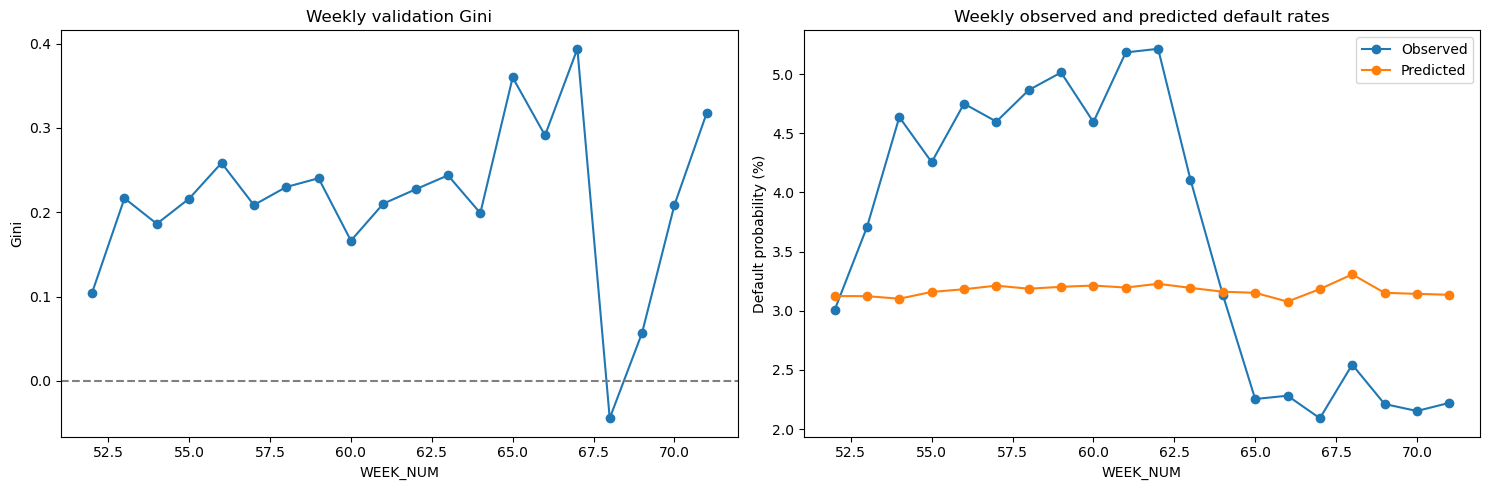

In [12]:
weekly_rows = []
for week, group in validation_predictions.groupby("WEEK_NUM", sort=True):
    if group["target"].nunique() == 2:
        week_auc = roc_auc_score(group["target"], group["probability_default"])
    else:
        week_auc = np.nan
    weekly_rows.append({
        "WEEK_NUM": int(week),
        "applications": len(group),
        "defaults": int(group["target"].sum()),
        "actual_default_rate": group["target"].mean(),
        "mean_predicted_probability": group["probability_default"].mean(),
        "roc_auc": week_auc,
        "gini": 2 * week_auc - 1 if pd.notna(week_auc) else np.nan,
        "brier_score": brier_score_loss(group["target"], group["probability_default"]),
        "calibration_gap": group["probability_default"].mean() - group["target"].mean(),
    })

weekly_metrics = pd.DataFrame(weekly_rows)
weekly_metrics.to_csv(report_dir / "weekly_validation_metrics.csv", index=False)
display(weekly_metrics.style.format({
    "applications": "{:,.0f}",
    "defaults": "{:,.0f}",
    "actual_default_rate": "{:.3%}",
    "mean_predicted_probability": "{:.3%}",
    "roc_auc": "{:.4f}",
    "gini": "{:.4f}",
    "brier_score": "{:.5f}",
    "calibration_gap": "{:.3%}",
}))

valid_week_numbers = weekly_metrics["WEEK_NUM"].to_numpy()
gini_slope, gini_intercept = np.polyfit(valid_week_numbers, weekly_metrics["gini"], 1)
gini_trend = gini_intercept + gini_slope * valid_week_numbers
gini_residual_standard_deviation = np.std(weekly_metrics["gini"] - gini_trend, ddof=0)
development_stability_metric = (
    weekly_metrics["gini"].mean()
    + 88.0 * min(0.0, gini_slope)
    - 0.5 * gini_residual_standard_deviation
)
weekly_summary = pd.Series({
    "mean_weekly_gini": weekly_metrics["gini"].mean(),
    "standard_deviation_weekly_gini": weekly_metrics["gini"].std(ddof=0),
    "minimum_weekly_gini": weekly_metrics["gini"].min(),
    "maximum_weekly_gini": weekly_metrics["gini"].max(),
    "weekly_gini_slope": gini_slope,
    "gini_residual_standard_deviation": gini_residual_standard_deviation,
    "development_stability_metric": development_stability_metric,
    "weeks_with_negative_gini": int(weekly_metrics["gini"].lt(0).sum()),
    "mean_absolute_weekly_calibration_gap": weekly_metrics["calibration_gap"].abs().mean(),
}, name="value")
weekly_summary.to_csv(report_dir / "weekly_validation_summary.csv")
display(weekly_summary.to_frame().style.format("{:.5f}"))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(weekly_metrics["WEEK_NUM"], weekly_metrics["gini"], marker="o")
axes[0].axhline(0, color="grey", linestyle="--")
axes[0].set_title("Weekly validation Gini")
axes[0].set_xlabel("WEEK_NUM")
axes[0].set_ylabel("Gini")

axes[1].plot(weekly_metrics["WEEK_NUM"], 100 * weekly_metrics["actual_default_rate"], marker="o", label="Observed")
axes[1].plot(weekly_metrics["WEEK_NUM"], 100 * weekly_metrics["mean_predicted_probability"], marker="o", label="Predicted")
axes[1].set_title("Weekly observed and predicted default rates")
axes[1].set_xlabel("WEEK_NUM")
axes[1].set_ylabel("Default probability (%)")
axes[1].legend()

fig.tight_layout()
plt.show()

## Inspect model coefficients carefully

Because preprocessing standardized the columns, coefficient magnitudes are more comparable than raw-unit coefficients. A positive coefficient increases the model's estimated log-odds of default; a negative coefficient decreases them.

These are conditional associations within this ten-feature model. They do not prove that a feature causes default. Correlated predictors can also divide or reverse apparent effects. Missing-indicator coefficients are scaled too, so read their direction rather than interpreting them as a direct 0-to-1 odds change.

In [13]:
preprocessor = baseline_model.named_steps["preprocess"]
prepared_feature_names = preprocessor.get_feature_names_out(selected_features)
coefficients = pd.DataFrame({
    "prepared_feature": prepared_feature_names,
    "coefficient": baseline_model.named_steps["model"].coef_[0],
})
coefficients["direction"] = np.where(coefficients["coefficient"] >= 0, "higher estimated risk", "lower estimated risk")
coefficients["absolute_coefficient"] = coefficients["coefficient"].abs()
coefficients = coefficients.sort_values("absolute_coefficient", ascending=False).reset_index(drop=True)
coefficients.to_csv(report_dir / "logistic_coefficients.csv", index=False)

display(coefficients.style.format({
    "coefficient": "{:.4f}",
    "absolute_coefficient": "{:.4f}",
}))

,prepared_feature,coefficient,direction,absolute_coefficient
0,credamount_770A,0.1286,higher estimated risk,0.1286
1,applications30d_658L,0.1258,higher estimated risk,0.1258
2,avgdpdtolclosure24_3658938P,0.1162,higher estimated risk,0.1162
3,totaldebt_9A,0.0888,higher estimated risk,0.0888
4,maininc_215A,-0.0816,lower estimated risk,0.0816
5,annuity_780A,-0.0585,lower estimated risk,0.0585
6,missingindicator_maininc_215A,-0.0514,lower estimated risk,0.0514
7,missingindicator_price_1097A,-0.0370,lower estimated risk,0.0370
8,missingindicator_avgdbddpdlast24m_3658932P,0.0314,higher estimated risk,0.0314
9,clientscnt12m_3712952L,0.0278,higher estimated risk,0.0278


## Save reproducible development artifacts

The saved pipeline contains both preprocessing and the fitted logistic model for weeks 0–51. Its filename clearly identifies it as a development artifact. We also save validation predictions as Parquet and compact CSV reports.

In [14]:
artifact_path = artifact_dir / "baseline_10_logistic_trained_weeks_0_51.joblib"
joblib.dump({
    "pipeline": baseline_model,
    "selected_features": selected_features,
    "training_weeks": [0, 51],
    "validation_weeks": [52, 71],
    "locked_holdout_weeks": [72, 91],
    "random_state": RANDOM_STATE,
}, artifact_path)

validation_predictions.to_parquet(
    report_dir / "validation_predictions.parquet",
    index=False,
)

print("Saved model artifact:", artifact_path)
print("Saved reports:", report_dir)

Saved model artifact: D:\Home Credit - Credit Risk Model Stability\artifacts\baseline_10_logistic_trained_weeks_0_51.joblib
Saved reports: D:\Home Credit - Credit Risk Model Stability\reports\baseline_10_logistic


## Conclusions and the next controlled experiment

Use the executed outputs above to answer:

1. Did the model beat random ranking and the constant probability baseline?
2. How different were the mean predicted probability and actual default rate?
3. Did observed default rates generally increase from risk decile 1 to 10?
4. How much did Gini vary across weeks 52–71?
5. Why is a `0.50` classification threshold usually unsuitable when defaults are rare?

Do not open the locked holdout yet. The next controlled experiment should keep the same logistic-regression settings and add the two income ratios. Comparing that model with this one isolates the contribution of simple feature engineering.